In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.svm import SVC

titanic_train_df = pd.read_csv("./data/train.csv")
titanic_test_df = pd.read_csv("./data/test.csv")
titanic_train_df.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
475,476,0,1,"Clifford, Mr. George Quincy",male,NaN,0,0,110465,52.0000,A14,S
854,855,0,2,"Carter, Mrs. Ernest Courtenay (Lilian Hughes)",female,44.0,1,0,244252,26.0000,NaN,S
780,781,1,3,"Ayoub, Miss. Banoura",female,13.0,0,0,2687,7.2292,NaN,C
415,416,0,3,"Meek, Mrs. Thomas (Annie Louise Rowley)",female,NaN,0,0,343095,8.0500,NaN,S
193,194,1,2,"Navratil, Master. Michel M",male,3.0,1,1,230080,26.0000,F2,S


## Exploratory Data Analysis (EDA)

### Sex / Survived rate

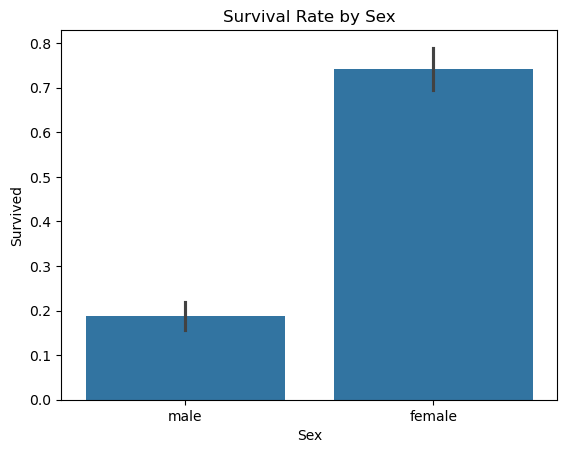

In [2]:
sns.barplot(x='Sex', y='Survived', data=titanic_train_df)
plt.title('Survival Rate by Sex')
plt.show()

In [3]:
titanic_train_df.groupby('Sex')['Survived'].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

### Passenger class / Survived rate

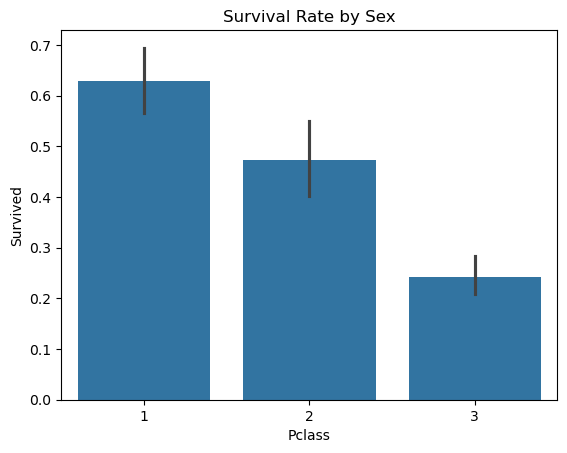

In [4]:
sns.barplot(x='Pclass', y='Survived', data=titanic_train_df)
plt.title('Survival Rate by Sex')
plt.show()

In [5]:
titanic_train_df.groupby('Pclass')['Survived'].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

## Other features / Survival

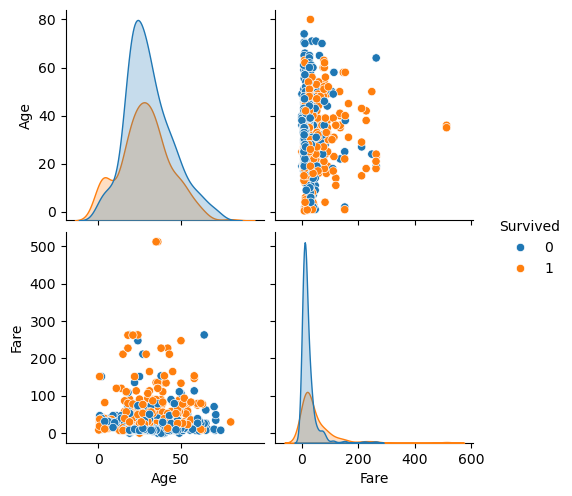

In [6]:
sns.pairplot(titanic_train_df[['Age', 'Fare', 'Survived']], hue='Survived')
plt.show()

## Linear Prediction

### Data preperation

In [7]:
def prepare_data_linear(df: pd.DataFrame, is_test_data: bool = False, scaler=None, fit_scaler=False) -> tuple:
    df = df.copy()
    df['Sex'] = LabelEncoder().fit_transform(df['Sex'])
    features = ['Sex', 'Pclass', 'Age', 'Fare']
    X = df[features]
    X = X.fillna(X.mean())

    if scaler is None:
        scaler = StandardScaler()
    if fit_scaler:
        X_scaled = scaler.fit_transform(X)
    else:
        X_scaled = scaler.transform(X)

    y = None
    if not is_test_data and 'Survived' in df.columns:
        y = df['Survived']

    return X_scaled, y, scaler

X_train, y_train, scaler = prepare_data_linear(titanic_train_df, is_test_data=False, fit_scaler=True)


### Logistic Regression

In [8]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

### Prediction

In [9]:
passenger_ids = titanic_test_df['PassengerId']

X_test, _, _ = prepare_data_linear(titanic_test_df, is_test_data=True, scaler=scaler, fit_scaler=False)
y_pred = model.predict(X_test)
submission = pd.DataFrame({
    'PassengerId': passenger_ids,
    'Survived': y_pred.astype(int)
})

submission.sample(5)

,PassengerId,Survived
48,940,1
342,1234,0
181,1073,0
274,1166,0
125,1017,1


In [10]:
submission.to_csv('submission_linear_classification.csv', index=False)

## Non linear prediction (Random Forest)

### Data Preparation

In [11]:
def prepare_data_tree(df: pd.DataFrame, is_test_data: bool = False) -> tuple:
    df = df.copy()
    df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

    X = df[['Sex', 'Pclass', 'Age', 'Fare']].copy()
    X = X.fillna(X.mean())

    y = None
    if not is_test_data and 'Survived' in df.columns:
        y = df['Survived']

    return X, y

X_train_all, y_train_all = prepare_data_tree(titanic_train_df)
X_train, X_val, y_train, y_val = train_test_split(X_train_all, y_train_all, test_size=0.2, random_state=42)

### Training

In [12]:
rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf.fit(X_train, y_train)
y_val_pred = rf.predict(X_val)
print("📊 Validation performance:")
print(classification_report(y_val, y_val_pred))

📊 Validation performance:
              precision    recall  f1-score   support

           0       0.79      0.90      0.84       105
           1       0.83      0.66      0.74        74

    accuracy                           0.80       179
   macro avg       0.81      0.78      0.79       179
weighted avg       0.81      0.80      0.80       179



### Prediction

In [13]:
X_test, _ = prepare_data_tree(titanic_test_df, is_test_data=True)
y_test_pred = rf.predict(X_test)

submission = pd.DataFrame({
    'PassengerId': titanic_test_df['PassengerId'],
    'Survived': y_test_pred
})
submission.to_csv('submission_rf.csv', index=False)

## Non linear prediction (Random Forest + Feature engineering)

### Data preparation

In [14]:
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    
    df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
    
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

    df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
    df['Title'] = df['Title'].replace(['Lady', 'Countess','Capt', 'Col',
                                       'Don', 'Dr', 'Major', 'Rev', 'Sir', 
                                       'Jonkheer', 'Dona'], 'Rare')
    df['Title'] = df['Title'].replace('Mlle', 'Miss')
    df['Title'] = df['Title'].replace('Ms', 'Miss')
    df['Title'] = df['Title'].replace('Mme', 'Mrs')
    title_map = {'Mr': 0, 'Miss': 1, 'Mrs': 2, 'Master': 3, 'Rare': 4}
    df['Title'] = df['Title'].map(title_map).fillna(4)

    df['AgeBin'] = pd.cut(df['Age'], bins=[0, 12, 20, 40, 60, 80], labels=[0, 1, 2, 3, 4])
    df['AgeBin'] = df['AgeBin'].astype(float)

    df['FareBin'] = pd.qcut(df['Fare'], 4, labels=[0, 1, 2, 3])
    df['FareBin'] = df['FareBin'].astype(float)

    return df

def prepare_data_tree_v2(df: pd.DataFrame, is_test_data=False) -> tuple:
    df = add_features(df)

    features = ['Sex', 'Pclass', 'FamilySize', 'IsAlone', 'Title', 'AgeBin', 'FareBin']
    df[features] = df[features].fillna(df[features].mean())

    X = df[features]
    y = df['Survived'] if not is_test_data and 'Survived' in df.columns else None

    return X, y

X_train, y_train = prepare_data_tree_v2(titanic_train_df)

### Training

In [15]:
rf = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=6, n_estimators=200, random_state=42)

### Prediciton

In [16]:
X_test, _ = prepare_data_tree_v2(titanic_test_df, is_test_data=True)
y_test_pred = rf.predict(X_test)
submission = pd.DataFrame({
    'PassengerId': titanic_test_df['PassengerId'],
    'Survived': y_test_pred
})
submission.to_csv('submission_with_features.csv', index=False)

## Non linear (SVN)

### Data Preparation

In [17]:
def prepare_data_svm(df: pd.DataFrame, scaler=None, fit_scaler=False, is_test_data=False):
    df = add_features(df)
    features = ['Sex', 'Pclass', 'FamilySize', 'IsAlone', 'Title', 'AgeBin', 'FareBin']
    df[features] = df[features].fillna(df[features].mean())

    X = df[features]

    if scaler is None:
        scaler = StandardScaler()

    if fit_scaler:
        X_scaled = scaler.fit_transform(X)
    else:
        X_scaled = scaler.transform(X)

    y = df['Survived'] if not is_test_data and 'Survived' in df.columns else None

    return X_scaled, y, scaler

X_scaled, y, scaler = prepare_data_svm(titanic_train_df, fit_scaler=True)
X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

### Training

In [18]:
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_model.fit(X_train, y_train)

y_val_pred = svm_model.predict(X_val)
print("📊 Validation performance:")
print(classification_report(y_val, y_val_pred))

📊 Validation performance:
              precision    recall  f1-score   support

           0       0.81      0.88      0.84       105
           1       0.80      0.72      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



### Prediction

In [19]:
X_test_scaled, _, _ = prepare_data_svm(titanic_test_df, scaler=scaler, is_test_data=True)
y_test_pred = svm_model.predict(X_test_scaled)

submission = pd.DataFrame({
    'PassengerId': titanic_test_df['PassengerId'],
    'Survived': y_test_pred
})
submission.to_csv('submission_svm.csv', index=False)

# Result from Kaggle:

- Linear regression: 0.75837
- Random forest: 0.77272
- Random forest (with features): 0.77751
- SVM: 0.78229

All results are as is in the code with no more tweaking